# 2.1. GIẢI THUẬT 1: CÂY QUYẾT ĐỊNH VÀ RỪNG CÂY

## 2.1.1. Ôn tập lý thuyết

**Nguồn câu hỏi:** *Lab - Thuat toan phan lop.pdf*, mục 2.1.1, trang 1-2.

Phần này trình bày đầy đủ 9 câu hỏi theo thứ tự trong tài liệu, kèm giải thích và mã Python minh họa. Các ô mã sử dụng bộ dữ liệu Iris có sẵn trong Scikit-learn và cần chạy từ trên xuống. Thư viện cần có: `scikit-learn`, `pandas`, `matplotlib`.

### Câu 1

**Câu hỏi:** Quy trình khai phá dữ liệu CRISP – DM (Cross Industry Standard Process for Data Mining) là gì? Quy trình khai phá dữ liệu SEMMA (Sample, Explore, Modify, Model, Access) là gì?

**Trả lời:**

**CRISP-DM** (*Cross-Industry Standard Process for Data Mining*) là quy trình chuẩn liên ngành hướng dẫn toàn bộ vòng đời một dự án khai phá dữ liệu. Quy trình có 6 giai đoạn:

| Giai đoạn | Nội dung chính |
|---|---|
| **Business Understanding - Hiểu nghiệp vụ** | Xác định vấn đề, mục tiêu, điều kiện triển khai và tiêu chí thành công; chuyển mục tiêu thành bài toán khai phá dữ liệu. |
| **Data Understanding - Hiểu dữ liệu** | Thu thập dữ liệu ban đầu, khảo sát đặc điểm và kiểm tra chất lượng dữ liệu. |
| **Data Preparation - Chuẩn bị dữ liệu** | Chọn dữ liệu, xử lý thiếu và sai lệch, tích hợp nguồn dữ liệu, mã hóa và tạo đặc trưng. |
| **Modeling - Xây dựng mô hình** | Chọn thuật toán, huấn luyện và điều chỉnh mô hình. |
| **Evaluation - Đánh giá** | Kiểm tra chất lượng kết quả và mức độ đáp ứng mục tiêu nghiệp vụ. |
| **Deployment - Triển khai** | Đưa mô hình hoặc kết quả phân tích vào sử dụng; theo dõi và bảo trì. |

Các giai đoạn có tính lặp: kết quả đánh giá chưa đạt có thể dẫn đến việc quay lại chuẩn bị dữ liệu hoặc xác định lại bài toán.

**SEMMA** là quy trình của SAS, tập trung vào các công việc phân tích dữ liệu và mô hình hóa, gồm 5 bước:

1. **Sample - Lấy mẫu:** chọn dữ liệu đủ đại diện, có quy mô phù hợp; phân chia dữ liệu cho huấn luyện và đánh giá.
2. **Explore - Khám phá:** dùng thống kê và trực quan hóa để tìm phân bố, mối liên hệ và bất thường.
3. **Modify - Biến đổi:** xử lý dữ liệu thiếu, lựa chọn, tạo và biến đổi đặc trưng.
4. **Model - Mô hình hóa:** xây dựng các mô hình để phát hiện quy luật hoặc dự đoán.
5. **Assess - Đánh giá:** so sánh mô hình, đánh giá tính hữu ích và độ tin cậy của kết quả.

**Lưu ý thuật ngữ:** tài liệu ghi “Access”, nhưng tên đúng của bước cuối trong SEMMA là **Assess**.

**Khác biệt:** CRISP-DM bao quát cả mục tiêu nghiệp vụ và triển khai; SEMMA tập trung vào quá trình xử lý dữ liệu, xây dựng và đánh giá mô hình. Cả hai đều cho phép lặp lại các bước khi cần.

Tham khảo: [IBM - CRISP-DM](https://www.ibm.com/docs/en/SS3RA7_18.5.0/pdf/ModelerCRISPDM.pdf), [SAS - SEMMA](https://support.sas.com/documentation/cdl/en/emcs/66392/HTML/default/n0pejm83csbja4n1xueveo2uoujy.htm).

### Câu 2

**Câu hỏi:** Cây quyết định hoạt động như thế nào? Hãy giải thích các thành phần chính (nút gốc, nút lá, nhánh) và cách cây đưa ra dự đoán.

**Trả lời:**

**Cây quyết định (Decision Tree)** dự đoán bằng một chuỗi điều kiện kiểm tra đặc trưng. Khi huấn luyện, thuật toán tìm các phép chia giúp tách dữ liệu thành những nhóm ngày càng đồng nhất về nhãn.

| Thành phần | Vai trò |
|---|---|
| **Nút gốc (root node)** | Nút đầu tiên, đại diện cho toàn bộ dữ liệu huấn luyện và chứa điều kiện kiểm tra đầu tiên. |
| **Nút trong (internal node)** | Chứa điều kiện kiểm tra tiếp theo, ví dụ `petal length <= 2.45`. |
| **Nhánh (branch)** | Đường nối ứng với kết quả của điều kiện, như đúng/sai hoặc nhỏ hơn/lớn hơn ngưỡng. |
| **Nút lá (leaf node)** | Điểm kết thúc, chứa kết quả dự đoán và thông tin phân bố nhãn. |

**Cách dự đoán:** bắt đầu tại nút gốc, kiểm tra đặc trưng của mẫu mới, đi theo nhánh phù hợp, tiếp tục đến khi gặp nút lá. Với phân loại, cây thường chọn lớp có tỷ lệ lớn nhất trong lá; với hồi quy, dự đoán thường là giá trị trung bình của các mẫu ở lá khi dùng tiêu chí sai số bình phương.

Ví dụ minh họa phân loại Iris:

```text
Chiều dài cánh hoa <= 2,45 cm?
├── Đúng: dự đoán Iris setosa
└── Sai: kiểm tra thêm chiều rộng cánh hoa
         ├── Nhánh 1: dự đoán Iris versicolor
         └── Nhánh 2: dự đoán Iris virginica
```

Cây dừng phát triển khi nút đã thuần hoặc gặp điều kiện dừng, chẳng hạn đạt `max_depth`, không đủ mẫu để chia hoặc phép chia không cải thiện tiêu chí. Cây quá sâu có thể học cả nhiễu và gây quá khớp.

### Câu 3

**Câu hỏi:** Các tiêu chí phân tách (splitting criteria) như Gini Index, Entropy, hay Information Gain được sử dụng trong cây quyết định là gì? Chúng khác nhau ra sao?

**Trả lời:**

Gọi $S$ là dữ liệu tại một nút, có $K$ lớp; $p_i$ là tỷ lệ mẫu thuộc lớp $i$.

**Gini Index** đo độ hỗn tạp của nút:

$$Gini(S)=1-\sum_{i=1}^{K}p_i^2.$$

Gini bằng 0 khi nút chỉ có một lớp. Với hai lớp, Gini lớn nhất bằng 0,5 khi tỷ lệ là 50%-50%.

**Entropy** đo độ bất định về nhãn tại nút:

$$H(S)=-\sum_{i=1}^{K}p_i\log_2 p_i,$$

với quy ước $0\log_2 0=0$. Entropy bằng 0 khi nút thuần. Giá trị lớn nhất là $\log_2 K$ khi các lớp có tỷ lệ bằng nhau; với hai lớp là 1 bit.

**Information Gain (IG)** là mức giảm Entropy sau phép chia thành $m$ nút con:

$$IG=H(S)-\sum_{j=1}^{m}\frac{|S_j|}{|S|}H(S_j).$$

Phần sau dấu trừ là **Entropy trung bình có trọng số**, không phải trung bình đơn giản khi các nút con có kích thước khác nhau.

| Đại lượng | Ý nghĩa | Cách dùng để chọn phép chia |
|---|---|---|
| Gini | Độ hỗn tạp của một nút | Chọn mức giảm Gini có trọng số lớn nhất. |
| Entropy | Độ bất định của một nút | Chọn Entropy có trọng số sau chia thấp nhất. |
| Information Gain | Entropy giảm được nhờ một phép chia | Chọn IG lớn nhất. |

Tương tự IG, mức giảm Gini là:

$$\Delta Gini=Gini(S)-\sum_{j=1}^{m}\frac{|S_j|}{|S|}Gini(S_j).$$

Ở cùng một nút cha, tối thiểu hóa Entropy sau chia tương đương với tối đa hóa IG. Gini và Entropy thường chọn các phép chia gần giống nhau, nhưng không bắt buộc cho cùng một cây. Gini không cần tính logarit; điều này không đồng nghĩa nó luôn dự đoán tốt hơn.

**Ví dụ dễ nhớ - cô Tấm lựa đậu:** rổ có 5 đậu đỏ và 5 đậu trắng thì Gini = 0,5 và Entropy = 1 bit. Nếu lựa thành hai rổ thuần, mỗi rổ một loại, cả Gini lẫn Entropy sau chia đều bằng 0; IG = 1 - 0 = 1 bit. Đây là phép chia lý tưởng để minh họa; thực tế một phép chia có thể vẫn để lẫn các lớp.

Trong `DecisionTreeClassifier`, có thể chọn `criterion='gini'` hoặc `criterion='entropy'`; lựa chọn sau sử dụng độ lợi thông tin Shannon khi tìm phép chia. Tham khảo: [Scikit-learn - DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).

### Câu 4

**Câu hỏi:** Rừng cây (Random Forest) là gì? Nó khác gì so với một cây quyết định đơn lẻ? Tại sao Random Forest thường có hiệu suất tốt hơn cây quyết định trong các bài toán phân loại?

**Trả lời:**

**Random Forest** là mô hình học tổ hợp gồm nhiều cây quyết định có tính ngẫu nhiên. Với thiết lập phổ biến:

1. Mỗi cây học trên một mẫu **bootstrap**: lấy mẫu có hoàn lại từ tập huấn luyện.
2. Tại mỗi nút, cây chỉ xét một tập con đặc trưng được chọn ngẫu nhiên để tìm phép chia.
3. Kết hợp dự đoán của các cây để đưa ra kết quả chung.

Về trực giác, có thể hình dung phân loại bằng biểu quyết của nhiều cây. Cụ thể trong `RandomForestClassifier` của Scikit-learn, mô hình **lấy trung bình xác suất lớp do các cây dự đoán**, rồi chọn lớp có xác suất trung bình lớn nhất. Với hồi quy, rừng thường lấy trung bình các giá trị dự đoán.

| Tiêu chí | Một cây quyết định | Random Forest |
|---|---|---|
| Cấu trúc | Một cây | Nhiều cây |
| Dữ liệu/đặc trưng | Một cây học các điều kiện trên dữ liệu | Tạo sự đa dạng bằng bootstrap và tập con đặc trưng |
| Khả năng giải thích | Dễ theo dõi đường đi nếu cây nhỏ | Khó diễn giải toàn bộ rừng |
| Độ ổn định | Có thể thay đổi nhiều khi dữ liệu thay đổi ít | Thường ổn định hơn |
| Tài nguyên | Thường ít tốn thời gian và bộ nhớ | Tốn tài nguyên hơn |

**Vì sao thường tốt hơn?** Một cây sâu có phương sai cao. Kết hợp nhiều cây đủ khác nhau giúp các sai lệch ngẫu nhiên bù trừ, giảm phương sai và thường giảm quá khớp so với một cây sâu. Việc chọn ngẫu nhiên đặc trưng giúp giảm tương quan giữa các cây. Tuy nhiên, Random Forest không bảo đảm luôn tốt hơn trên mọi tập dữ liệu và vẫn có thể quá khớp.

Tham khảo: [Scikit-learn - RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

### Câu 5

**Câu hỏi:** Những ưu điểm và hạn chế của cây quyết định và Random Forest là gì? Trong trường hợp nào thì cây quyết định có thể hoạt động kém hiệu quả?

**Trả lời:**

| Mô hình | Ưu điểm | Hạn chế |
|---|---|---|
| **Cây quyết định** | Dễ giải thích khi cây nhỏ; biểu diễn quan hệ phi tuyến và tương tác đặc trưng; không đòi hỏi chuẩn hóa thang đo thông thường; dự đoán nhanh. | Dễ quá khớp nếu không kiểm soát; nhạy với thay đổi dữ liệu; chia tham lam nên không bảo đảm cây tối ưu toàn cục; cây sâu khó diễn giải. |
| **Random Forest** | Thường tổng quát hóa và ổn định tốt hơn một cây sâu; mô hình hóa quan hệ phi tuyến; có thể huấn luyện các cây song song; hỗ trợ ước lượng tầm quan trọng đặc trưng. | Tốn bộ nhớ và thời gian hơn; khó giải thích từng dự đoán; độ quan trọng dựa trên impurity có thể thiên lệch; không tự giải quyết mọi vấn đề mất cân bằng lớp hoặc rò rỉ dữ liệu. |

**Cây quyết định có thể kém hiệu quả khi:**

- Dữ liệu ít nhưng nhiều nhiễu, nhãn sai hoặc cây được phép phát triển quá sâu: dễ học thuộc dữ liệu huấn luyện.
- Ranh giới phân lớp chéo hoặc trơn, trong khi cây dùng các phép chia theo từng trục: có thể cần nhiều nút để xấp xỉ.
- Có nhiều đặc trưng không liên quan hoặc nhiều giá trị khác nhau: tăng khả năng tìm được phép chia trông tốt do ngẫu nhiên.
- Dữ liệu mất cân bằng mạnh: độ chính xác tổng thể cao vẫn có thể che giấu việc bỏ sót lớp thiểu số.
- Cây bị giới hạn quá chặt, chẳng hạn `max_depth` quá nhỏ: gây thiếu khớp.

**Cách cải thiện:** điều chỉnh `max_depth`, `min_samples_split`, `min_samples_leaf`; cắt tỉa bằng `ccp_alpha`; đánh giá bằng cross-validation; dùng chỉ số phù hợp như F1-macro/recall và cân nhắc `class_weight` khi mất cân bằng. Cây không cần scaling thông thường nhưng dữ liệu đầu vào vẫn cần được xử lý và biểu diễn phù hợp với thư viện sử dụng.

### Câu 6

**Câu hỏi:** Viết đoạn code mẫu bằng Python (sử dụng Scikit-learn) để xây dựng một mô hình cây quyết định không? Hãy mô tả các bước thực hiện.

**Trả lời:**

Ví dụ sử dụng Iris, bộ dữ liệu phân loại 3 loài hoa dựa trên 4 đặc trưng số.

1. Nạp dữ liệu và tách đặc trưng `X`, nhãn `y`.
2. Giữ riêng 20% dữ liệu làm **test**; phần còn lại là **development**. Tách development thành train/validation để minh họa mô hình ban đầu.
3. Khởi tạo `DecisionTreeClassifier` và dùng `fit()` trên train.
4. Dùng `predict()` trên validation, đánh giá bằng accuracy, F1-macro và confusion matrix.
5. Có thể dùng `plot_tree()` để xem các điều kiện đã học.

`stratify` giữ tương đối tỷ lệ lớp khi chia; `random_state` giúp tái lập. Iris đã có các đặc trưng số và không thiếu dữ liệu nên không cần tiền xử lý thêm. **Tập test chỉ được dùng ở cuối câu 9**, sau khi chọn siêu tham số. Các câu 7-9 dùng lại biến dữ liệu được tạo trong ô mã này.

Train: 90, validation: 30, test: 30
Validation accuracy: 0.9
Validation F1-macro: 0.8997
Confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



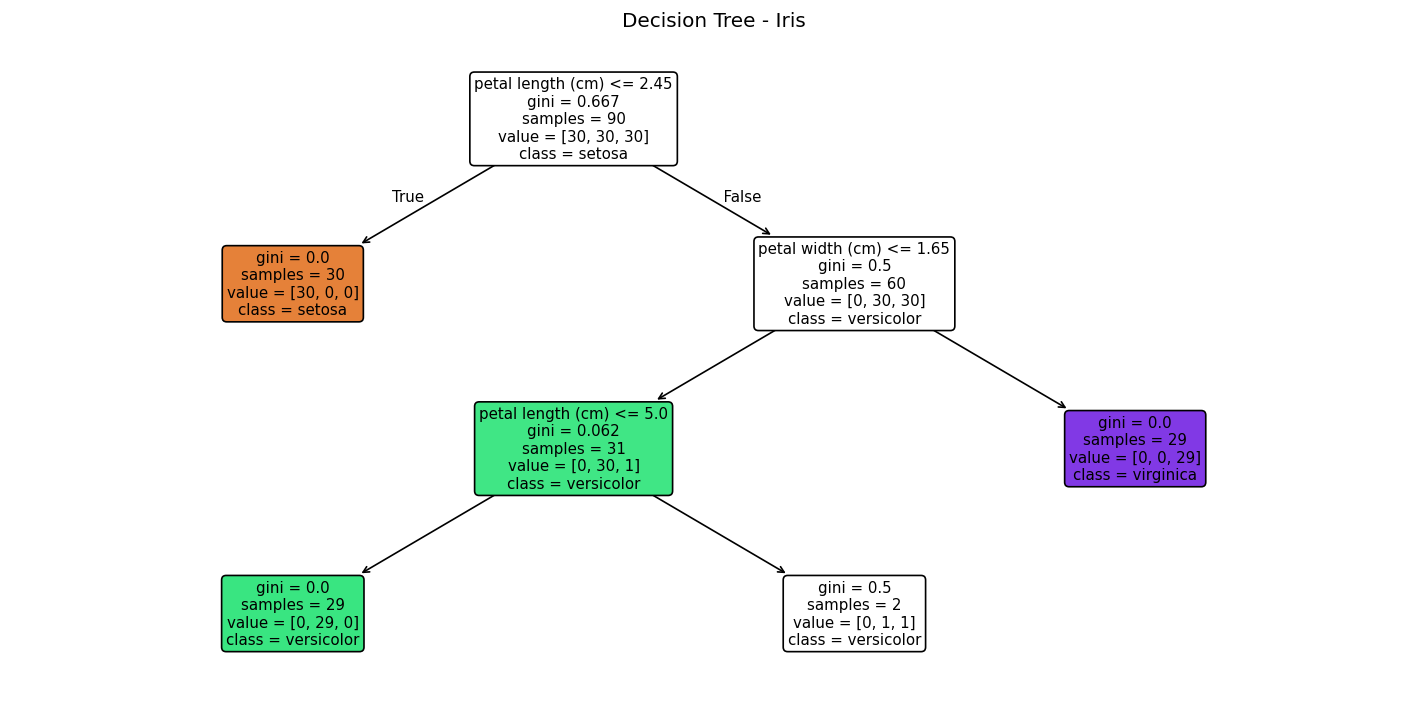

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import pandas as pd

iris = load_iris()
X, y = iris.data, iris.target

# Giữ riêng test để đánh giá cuối cùng.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=42
)
print(f'Train: {len(y_train)}, validation: {len(y_valid)}, test: {len(y_test)}')

dt = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
dt.fit(X_train, y_train)
y_valid_dt = dt.predict(X_valid)
print('Validation accuracy:', round(accuracy_score(y_valid, y_valid_dt), 4))
print('Validation F1-macro:', round(f1_score(y_valid, y_valid_dt, average='macro'), 4))
print('Confusion matrix:\n', confusion_matrix(y_valid, y_valid_dt))
print(classification_report(y_valid, y_valid_dt, target_names=iris.target_names, zero_division=0))

plt.figure(figsize=(12, 6))
plot_tree(dt, feature_names=iris.feature_names, class_names=list(iris.target_names),
          filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree - Iris')
plt.tight_layout()
plt.show()

### Câu 7

**Câu hỏi:** Làm thế nào để triển khai một mô hình Random Forest trong Python? Bạn thường thiết lập các tham số nào (ví dụ: n_estimators, max_depth)?

**Trả lời:**

Sử dụng `RandomForestClassifier`, khởi tạo tham số, huấn luyện bằng `fit()` rồi dự đoán bằng `predict()`. Dữ liệu train/validation trong ví dụ tiếp tục lấy từ câu 6.

| Tham số | Ý nghĩa |
|---|---|
| `n_estimators` | Số cây trong rừng; nhiều cây thường giúp kết quả ổn định hơn nhưng tăng tài nguyên. |
| `max_depth` | Độ sâu tối đa mỗi cây; `None` cho phép phát triển đến các điều kiện dừng khác. |
| `max_features` | Số đặc trưng được xét tại mỗi lần chia; `'sqrt'` xét khoảng căn bậc hai số đặc trưng. |
| `min_samples_split` | Số mẫu tối thiểu để một nút được phép chia. |
| `min_samples_leaf` | Số mẫu tối thiểu cần có ở mỗi lá; tăng tham số này thường làm mô hình bớt phức tạp. |
| `bootstrap` | Có lấy mẫu huấn luyện có hoàn lại cho từng cây hay không. |
| `class_weight` | Trọng số lớp, có thể thử `'balanced'` khi mất cân bằng. |
| `random_state` | Kiểm soát tính ngẫu nhiên để tái lập. |
| `n_jobs` | Số tác vụ song song; `-1` dùng các bộ xử lý khả dụng. |

Các giá trị dưới đây là cấu hình minh họa, không phải bộ tham số tối ưu cho mọi dữ liệu. `n_jobs=1` giúp ví dụ nhẹ và dễ chạy trong môi trường học tập.

In [2]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    max_features='sqrt',
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=True,
    random_state=42,
    n_jobs=1
)
rf.fit(X_train, y_train)
y_valid_rf = rf.predict(X_valid)
print('Validation accuracy:', round(accuracy_score(y_valid, y_valid_rf), 4))
print('Validation F1-macro:', round(f1_score(y_valid, y_valid_rf, average='macro'), 4))
print(classification_report(y_valid, y_valid_rf, target_names=iris.target_names, zero_division=0))

Validation accuracy: 0.9333
Validation F1-macro: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



### Câu 8

**Câu hỏi:** Làm thế nào để đánh giá tầm quan trọng của các đặc trưng (feature importance) trong Random Forest bằng Python?

**Trả lời:**

Có hai cách phổ biến:

**1. Mean Decrease in Impurity (MDI):** đọc `rf.feature_importances_` sau huấn luyện. Chỉ số tổng hợp mức giảm impurity có trọng số do mỗi đặc trưng mang lại trên các cây, rồi chuẩn hóa. Giá trị cao cho thấy mô hình sử dụng đặc trưng nhiều hơn theo tiêu chí này; không phải chỉ là số lần đặc trưng xuất hiện. Cách tính dựa trên train và có thể ưu tiên đặc trưng có nhiều giá trị khác nhau.

**2. Permutation importance:** dùng `permutation_importance()` trên validation. Xáo trộn từng cột làm mất liên hệ của cột đó với nhãn, rồi đo mức giảm điểm dự đoán. Điểm giảm nhiều gợi ý mô hình phụ thuộc mạnh vào đặc trưng đó. Lặp lại giúp xem độ biến động của ước lượng.

Ví dụ sau in bảng MDI và permutation importance theo F1-macro trên validation. Hai thước đo có đơn vị khác nhau, không so trực tiếp giá trị số giữa chúng. Đặc trưng tương quan có thể chia sẻ hoặc che lấp tầm quan trọng của nhau; điểm gần 0 hay âm không chứng minh đặc trưng vô ích trong mọi mô hình. Những chỉ số này không chứng minh quan hệ nhân quả.

Tham khảo: [Scikit-learn - Permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html), [MDI và hạn chế](https://scikit-learn.org/stable/modules/ensemble.html#feature-importance-evaluation).

                      MDI  Permutation mean (F1 decrease)  Permutation std
petal width (cm)   0.4599                          0.1153           0.0547
petal length (cm)  0.4037                          0.0811           0.0398
sepal length (cm)  0.1262                          0.0202           0.0165
sepal width (cm)   0.0102                          0.0000           0.0000


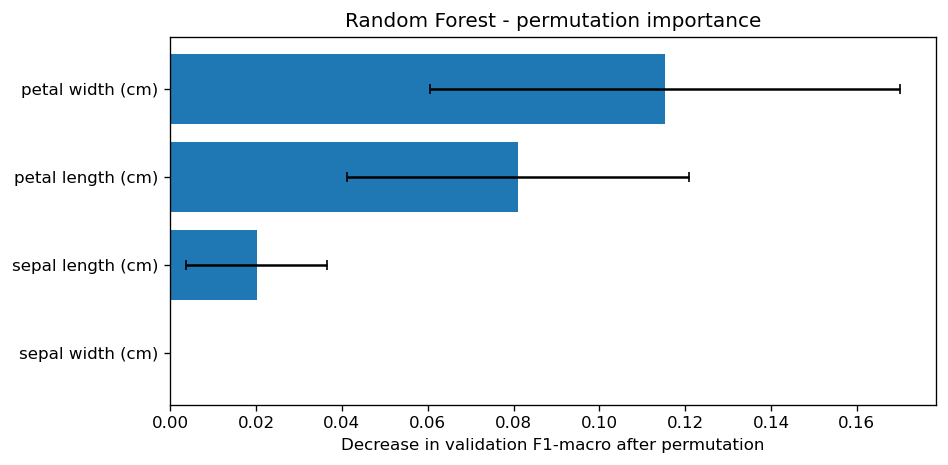

In [3]:
from sklearn.inspection import permutation_importance

mdi = pd.Series(rf.feature_importances_, index=iris.feature_names, name='MDI')
perm = permutation_importance(
    rf, X_valid, y_valid, scoring='f1_macro',
    n_repeats=20, random_state=42, n_jobs=1
)
importance_table = pd.DataFrame({
    'MDI': mdi,
    'Permutation mean (F1 decrease)': perm.importances_mean,
    'Permutation std': perm.importances_std
}).sort_values('Permutation mean (F1 decrease)', ascending=False)
print(importance_table.round(4).to_string())

order = perm.importances_mean.argsort()
plt.figure(figsize=(8, 4))
plt.barh([iris.feature_names[i] for i in order], perm.importances_mean[order],
         xerr=perm.importances_std[order], capsize=3)
plt.axvline(0, color='gray', linewidth=1)
plt.xlabel('Decrease in validation F1-macro after permutation')
plt.title('Random Forest - permutation importance')
plt.tight_layout()
plt.show()

### Câu 9

**Câu hỏi:** Điều chỉnh siêu tham số (hyperparameter tuning) cho cây quyết định hoặc Random Forest chưa? Hãy mô tả cách bạn sử dụng GridSearchCV hoặc RandomizedSearchCV.

**Trả lời:**

**Điều chỉnh siêu tham số** là tìm cấu hình giúp mô hình tổng quát hóa tốt, chẳng hạn độ sâu cây hoặc số cây trong rừng. Quy trình minh họa:

1. Giữ riêng test trước khi tìm kiếm. Chỉ dùng dữ liệu development cho lựa chọn siêu tham số.
2. Chọn miền giá trị tham số và thước đo phù hợp. Ví dụ Iris có 3 lớp nên dùng `f1_macro`; bài toán nhị phân có thể dùng `roc_auc` nếu phù hợp mục tiêu.
3. Dùng `StratifiedKFold` để giữ tỷ lệ lớp tương đối ở mỗi fold.
4. Với mỗi cấu hình, huấn luyện/đánh giá trên các fold; chọn điểm validation trung bình tốt nhất.
5. Với `refit=True`, tìm kiếm tự huấn luyện lại cấu hình tốt nhất trên toàn bộ development. Đọc `best_params_`, `best_score_`, `best_estimator_`.
6. Nếu thử nhiều họ mô hình, chọn mô hình bằng điểm cross-validation rồi mới đánh giá mô hình đã chọn trên test.

| Công cụ | Cách tìm | Phù hợp khi |
|---|---|---|
| `GridSearchCV` | Thử mọi tổ hợp trong lưới | Lưới nhỏ, cần khảo sát đầy đủ các cấu hình đã liệt kê. |
| `RandomizedSearchCV` | Lấy ngẫu nhiên `n_iter` cấu hình từ miền tìm kiếm | Miền rộng hoặc ngân sách tính toán hạn chế. |

**Ví dụ 1:** dùng GridSearchCV cho cây quyết định. **Ví dụ 2:** dùng RandomizedSearchCV cho Random Forest. Cả hai dùng cùng các fold và cùng F1-macro để so sánh. Đây là quy trình minh họa, không khẳng định đã tìm được tối ưu toàn cục.

Nếu cần điền dữ liệu thiếu, mã hóa hoặc chọn đặc trưng, nên đặt các bước học từ dữ liệu trong `Pipeline` để chúng chỉ được fit trên phần train của từng fold, tránh rò rỉ dữ liệu.

Tham khảo: [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html).

In [4]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid={
        'criterion': ['gini', 'entropy'],
        'max_depth': [2, 3, None],
        'min_samples_leaf': [1, 2, 4]
    },
    scoring='f1_macro', cv=cv, refit=True, n_jobs=1
)
grid_dt.fit(X_dev, y_dev)
print('Decision Tree - best parameters:', grid_dt.best_params_)
print('Decision Tree - mean CV F1-macro:', round(grid_dt.best_score_, 4))

Decision Tree - best parameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}
Decision Tree - mean CV F1-macro: 0.958


In [5]:
random_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=1),
    param_distributions={
        'n_estimators': [50, 100, 150],
        'max_depth': [3, 5, None],
        'min_samples_leaf': [1, 2],
        'max_features': ['sqrt', None]
    },
    n_iter=6, scoring='f1_macro', cv=cv, refit=True,
    random_state=42, n_jobs=1
)
random_rf.fit(X_dev, y_dev)
print('Random Forest - best parameters:', random_rf.best_params_)
print('Random Forest - mean CV F1-macro:', round(random_rf.best_score_, 4))

# Chọn theo CV; không dùng điểm test để quyết định mô hình hay tham số.
searches = {'Decision Tree': grid_dt, 'Random Forest': random_rf}
best_name = max(searches, key=lambda name: searches[name].best_score_)
best_model = searches[best_name].best_estimator_
y_pred_final = best_model.predict(X_test)
print('\nModel selected by CV:', best_name)
print('Final test accuracy:', round(accuracy_score(y_test, y_pred_final), 4))
print('Final test F1-macro:', round(f1_score(y_test, y_pred_final, average='macro'), 4))
print('Final test confusion matrix:\n', confusion_matrix(y_test, y_pred_final))
print(classification_report(y_test, y_pred_final, target_names=iris.target_names, zero_division=0))

Random Forest - best parameters: {'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 5}
Random Forest - mean CV F1-macro: 0.9663

Model selected by CV: Random Forest
Final test accuracy: 0.9667
Final test F1-macro: 0.9666
Final test confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



**Cách đọc kết quả:** `best_score_` là điểm cross-validation trung bình của cấu hình được chọn, không phải điểm test. Kết quả test đánh giá mô hình đã chốt trên 30 mẫu Iris chưa dùng để huấn luyện hoặc chọn cấu hình. Tập dữ liệu nhỏ nên một lần chia không đủ để khẳng định mô hình nào luôn tốt hơn; không điều chỉnh lại tham số dựa trên điểm test này.